In [33]:
import glob
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

dx, dt = 0.01, 0.005  # match grid_2d.f90

files = sorted(glob.glob('../src/u_*.dat'))
# file rows = i (first Fortran index), cols = j; transpose so i is on the x-axis
U = np.stack([np.loadtxt(f).T for f in files])
n = U.shape[1]
extent = [0, n*dx, 0, n*dx]
print(f'{len(files)} frames, grid {U.shape[1:]}, min {U.min():.3f}, max {U.max():.3f}')

201 frames, grid (100, 100), min 0.000, max 63.662


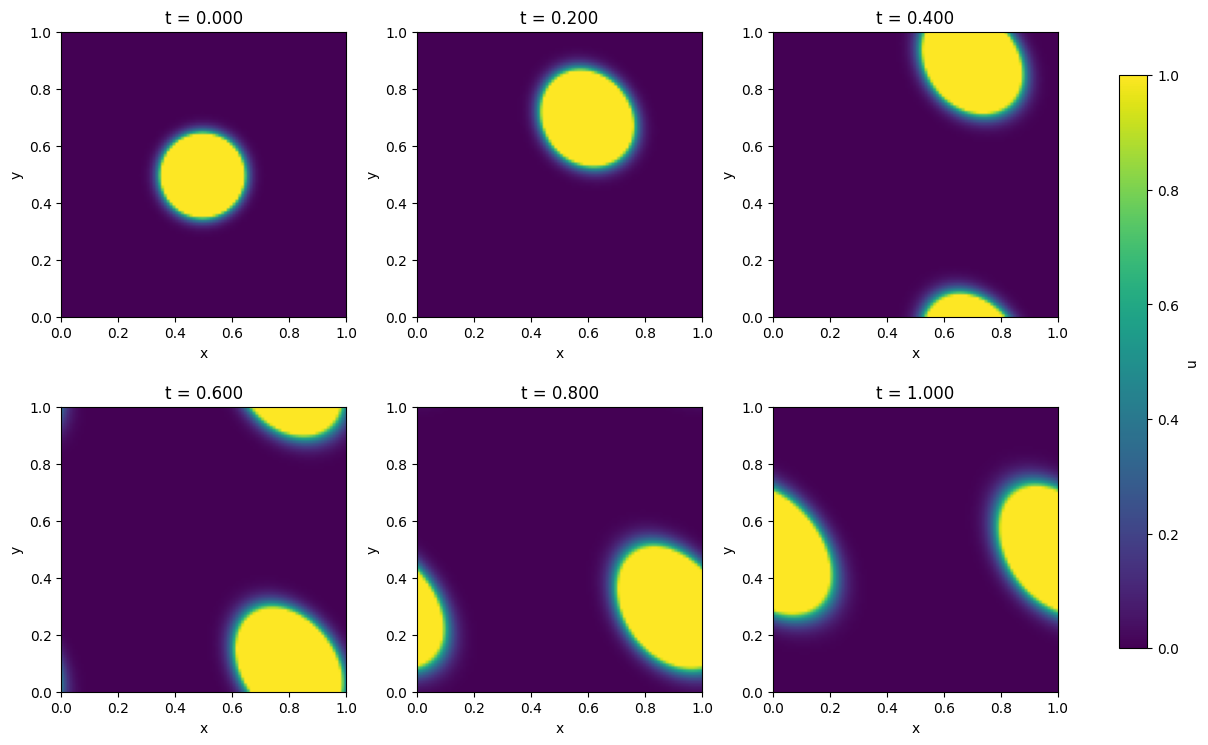

In [34]:
# Snapshots
steps = np.linspace(0, len(U)-1, 6, dtype=int)
fig, axes = plt.subplots(2, 3, figsize=(12, 7.5), constrained_layout=True)
for ax, k in zip(axes.flat, steps):
    im = ax.imshow(U[k], origin='lower', extent=extent, cmap='viridis', vmin=0, vmax=1)
    ax.set_title(f't = {k*dt:.3f}')
    ax.set_xlabel('x'); ax.set_ylabel('y')
fig.colorbar(im, ax=axes, shrink=0.8, label='u')
plt.show()

In [35]:
# Animation
fig, ax = plt.subplots(figsize=(5.5, 5))
im = ax.imshow(U[0], origin='lower', extent=extent, cmap='viridis', vmin=0, vmax=1)
fig.colorbar(im, ax=ax, label='u')
ax.set_xlabel('x'); ax.set_ylabel('y')

def update(k):
    im.set_data(U[k])
    ax.set_title(f't = {k*dt:.3f}')
    return [im]

anim = FuncAnimation(fig, update, frames=range(0, len(U), 2), interval=50)
plt.close(fig)
HTML(anim.to_jshtml())